In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
X = pd.read_csv("../data/X_train.csv")
y = pd.read_csv("../data/y_train.csv")

df = X.merge(y, on="Index")


In [5]:
X.head

<bound method NDFrame.head of        Index patient_id cohort  sexM    gene  age_at_diagnosis   age   ledd  \
0          0   IPLP5212      A     0  LRRK2+              48.5  52.1  607.0   
1          1   IPLP5212      A     0  LRRK2+              48.5  53.0  666.0   
2          2   IPLP5212      A     0  LRRK2+              48.5  53.9  717.0   
3          3   IPLP5212      A     0  LRRK2+              48.5  54.8  770.0   
4          4   IPLP5212      A     0  LRRK2+              48.5  56.9  885.0   
...      ...        ...    ...   ...     ...               ...   ...    ...   
44585  55598   CZTX7061      A     1  LRRK2+              59.0  60.6    NaN   
44586  55599   CZTX7061      A     1  LRRK2+              59.0  61.1    NaN   
44587  55600   CZTX7061      A     1  LRRK2+              59.0  61.8    NaN   
44588  55601   CZTX7061      A     1  LRRK2+              59.0  62.6    NaN   
44589  55602   CZTX7061      A     1  LRRK2+              59.0  63.5    NaN   

       time_since_int

In [6]:
y.head

<bound method NDFrame.head of        Index  target
0          0    34.7
1          1    38.1
2          2    41.6
3          3    44.9
4          4    52.0
...      ...     ...
44585  55598     2.9
44586  55599     3.4
44587  55600     4.3
44588  55601     5.3
44589  55602     6.8

[44590 rows x 2 columns]>

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44590 entries, 0 to 44589
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Index                  44590 non-null  int64  
 1   patient_id             44590 non-null  str    
 2   cohort                 44590 non-null  str    
 3   sexM                   44590 non-null  int64  
 4   gene                   30158 non-null  str    
 5   age_at_diagnosis       42271 non-null  float64
 6   age                    44590 non-null  float64
 7   ledd                   28252 non-null  float64
 8   time_since_intake_on   23912 non-null  float64
 9   time_since_intake_off  9474 non-null   float64
 10  rater_id               44590 non-null  str    
 11  on                     31370 non-null  float64
 12  off                    25677 non-null  float64
 13  target                 44590 non-null  float64
dtypes: float64(8), int64(2), str(4)
memory usage: 4.8 MB


<Axes: xlabel='target', ylabel='Count'>

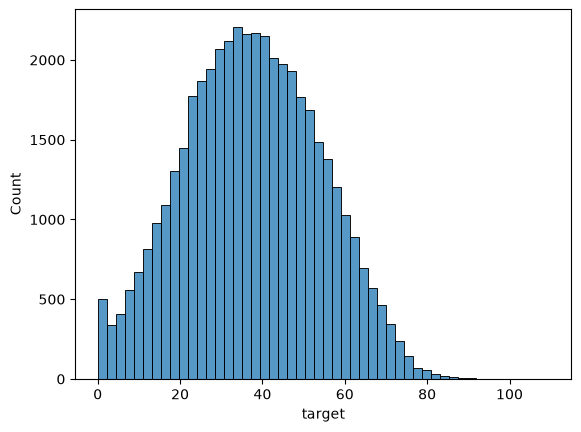

In [12]:
df["target"].describe()
sns.histplot(df["target"], bins=50)

In [ ]:
# valeur manquante impact target ?
for c in X:
    print(c, df.groupby(df[c].isna())["target"].mean().round(2).to_dict())

Index {False: 37.47}
patient_id {False: 37.47}
cohort {False: 37.47}
sexM {False: 37.47}
gene {False: 36.95, True: 38.56}
age_at_diagnosis {False: 37.44, True: 38.11}
age {False: 37.47}
ledd {False: 44.33, True: 25.62}
time_since_intake_on {False: 44.36, True: 29.51}
time_since_intake_off {False: 44.26, True: 35.64}
rater_id {False: 37.47}
on {False: 44.29, True: 21.29}
off {False: 32.37, True: 44.4}


In [18]:
#cohort, gene, sexM influencent-elles la cible ?
for c in ["cohort","gene","sexM"]:
    print(df.groupby(c, dropna=False)["target"].agg(["count","mean","std"]))


        count       mean        std
cohort                             
A       39636  37.945383  16.620751
B        4954  33.680299  14.967723
             count       mean        std
gene                                    
GBA+          6357  36.265235  17.165863
LRRK2+        7588  35.741645  16.419730
No Mutation  14250  38.280225  16.245477
OTHER+        1963  34.194244  17.472220
NaN          14432  38.559673  16.187717
      count      mean        std
sexM                            
0     17826  37.49972  16.423450
1     26764  37.45275  16.550536


In [ ]:
df.groupby("cohort")[["age", "age_at_diagnosis","ledd"]].mean()

,age,ledd
cohort,,
A,62.817625,647.140349
B,60.514352,555.327004


             off    target
off     1.000000  0.871191
target  0.871191  1.000000


count    25677.000000
mean        -5.376469
std          8.668206
min        -54.400000
25%        -10.400000
50%         -3.800000
75%          0.300000
max         30.600000
Name: err, dtype: float64

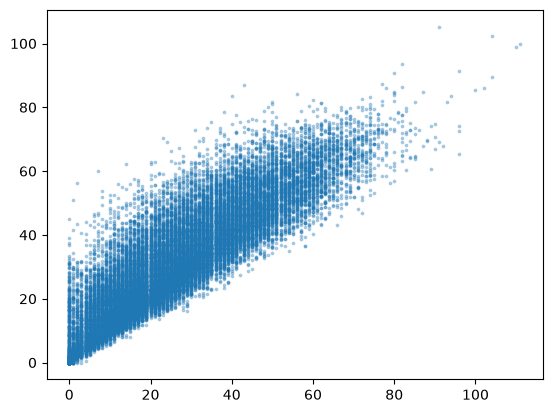

In [ ]:
#à quel point off et on prédisent-ils target ?

d = df.dropna(subset=["off"])
plt.scatter(d["off"], d["target"], s=3, alpha=.3)
print(d[["off","target"]].corr())

# l'erreur de mesure
d = d.assign(err = d["off"] - d["target"])
d["err"].describe()

              on    target
on      1.000000  0.668735
target  0.668735  1.000000


count    31370.000000
mean       -21.788495
std          9.874263
min        -64.100000
25%        -28.200000
50%        -21.200000
75%        -14.900000
max         22.900000
Name: err, dtype: float64

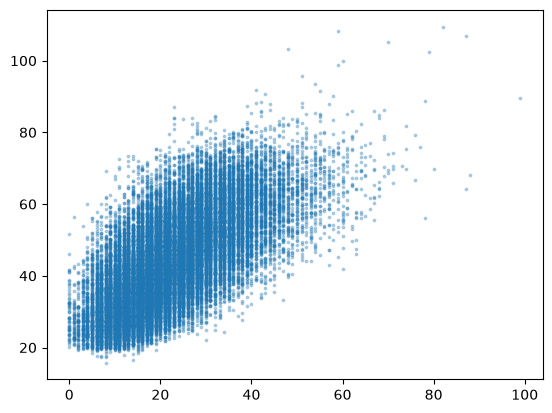

In [23]:
#à quel point off et on prédisent-ils target ?
d = df.dropna(subset=["on"])
plt.scatter(d["on"], d["target"], s=3, alpha=.3)
print(d[["on","target"]].corr())

# l'erreur de mesure
d = d.assign(err = d["on"] - d["target"])
d["err"].describe()